# Software Quality Insight: Apache Calcite



In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

ROOT = Path.cwd()
if not (ROOT / "data" / "processed").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "processed"
FIGURES = ROOT / "figures"
df = pd.read_csv(DATA / "calcite_module_release.csv")
modules = pd.read_csv(DATA / "module_defect_summary.csv")
components = pd.read_csv(DATA / "component_summary.csv")
releases = pd.read_csv(DATA / "release_summary.csv")
severity = pd.read_csv(DATA / "calcite_issue_severity_long.csv")
print(f"Rows: {len(df):,}; unique files: {df.module.nunique():,}; releases: {df.release_version.nunique()}")
df.head()

Rows: 19,751; unique files: 1,644; releases: 16


,module,contributor_count,churn_avg_proxy,commit_count_proxy,churn_lines_proxy,lines_added_proxy,lines_deleted_proxy,coupling_cbo_avg,coupling_cbo_sum,complexity_wmc_avg,...,defects_per_kloc,severity_issue_count,severity_unknown_count,severity_blocker_count,severity_critical_count,severity_major_count,severity_minor_count,severity_normal_count,severity_trivial_count,severity_enhancement_count
0,avatica-server/src/main/java/org/apache/calcit...,1,27.000000,1,27,33,6,2.000000,2.0,3.000000,...,0.0,0,0,0,0,0,0,0,0,0
1,avatica-server/src/main/java/org/apache/calcit...,1,91.000000,1,91,91,0,0.000000,0.0,9.000000,...,0.0,0,0,0,0,0,0,0,0,0
2,avatica-server/src/main/java/org/apache/calcit...,1,25.000000,1,25,31,6,6.000000,6.0,3.000000,...,0.0,0,0,0,0,0,0,0,0,0
3,avatica/src/main/java/org/apache/calcite/avati...,1,12.142857,7,85,139,54,9.333333,28.0,27.333333,...,0.0,0,0,0,0,0,0,0,0,0
4,avatica/src/main/java/org/apache/calcite/avati...,1,7.000000,5,35,104,69,11.000000,11.0,191.000000,...,0.0,0,0,0,0,0,0,0,0,0


## 1. Data quality and analysis grain
Each row represents a module file in a release. Check key uniqueness, missingness, valid ranges, and whether defect labels reconcile to linked severity records before interpreting patterns.

In [2]:
print("Duplicate module-release keys:", df.duplicated(["module", "release_version"]).sum())
display(df.isna().sum().sort_values(ascending=False).head(15).rename("missing values").to_frame())
print("Negative signed net-change values:", (df.churn_lines_proxy < 0).sum(), "(valid: additions minus deletions can be negative)")
print("Negative change-volume proxies:", (df.change_volume_proxy < 0).sum())
print("Defect total:", int(df.defect_count.sum()))
print("Severity issue total:", int(df.severity_issue_count.sum()))
print("Coverage available:", False)

Duplicate module-release keys: 0


,missing values
module,0
contributor_count,0
churn_avg_proxy,0
commit_count_proxy,0
churn_lines_proxy,0
lines_added_proxy,0
lines_deleted_proxy,0
coupling_cbo_avg,0
coupling_cbo_sum,0
complexity_wmc_avg,0


Negative signed net-change values: 1253 (valid: additions minus deletions can be negative)
Negative change-volume proxies: 0
Defect total: 2138
Severity issue total: 2138
Coverage available: False


## 2. Defects by module and component
Show raw repeated defect totals alongside release recurrence and size-adjusted rates. Size-adjusted rates are descriptive exposure measures, not risk probabilities.

,module,component,total_defects,releases_with_defects,defects_per_kloc_exposure
1268,core/src/main/java/org/apache/calcite/sql2rel/...,sql2rel,86,16,1.048665
353,core/src/main/java/org/apache/calcite/adapter/...,adapter,68,16,2.103635
1239,core/src/main/java/org/apache/calcite/sql/vali...,sql,66,16,0.843688
499,core/src/main/java/org/apache/calcite/plan/Rel...,plan,42,16,0.740780
1381,druid/src/main/java/org/apache/calcite/adapter...,adapter,39,8,3.729559
690,core/src/main/java/org/apache/calcite/rel/rel2...,rel,32,10,8.281573
638,core/src/main/java/org/apache/calcite/rel/meta...,rel,31,16,5.382879
695,core/src/main/java/org/apache/calcite/rel/rule...,rel,31,12,5.909264
584,core/src/main/java/org/apache/calcite/rel/core...,rel,30,16,4.651163
1168,core/src/main/java/org/apache/calcite/sql/type...,sql,30,16,10.787487


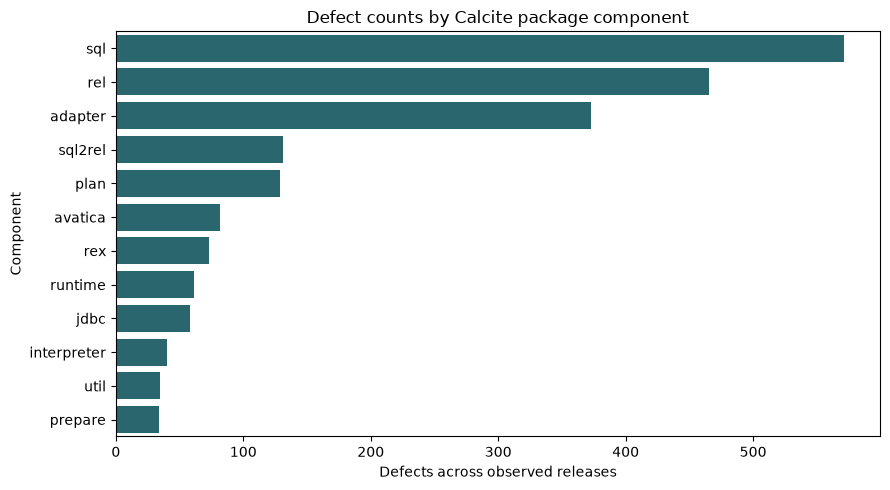

In [3]:
display(modules.sort_values(["total_defects", "releases_with_defects"], ascending=False).head(15)[["module", "component", "total_defects", "releases_with_defects", "defects_per_kloc_exposure"]])
top = components.sort_values("total_defects", ascending=False).head(12)
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=top, x="total_defects", y="component", color="#1f6f78", ax=ax)
ax.set(title="Defect counts by Calcite package component", xlabel="Defects across observed releases", ylabel="Component")
plt.tight_layout(); plt.show()

## 3. Complexity, coupling, and defect counts
Spearman correlations summarize monotonic association. Repeated files across releases and many zero-defect rows mean these values are exploratory, not independent-sample causal estimates.

,metric,spearman_rho,n
4,size_loc,0.275516,19751
2,coupling_cbo_sum,0.265697,19751
0,complexity_wmc_sum,0.261252,19751
1,complexity_wmc_avg,0.216926,19751
3,coupling_cbo_avg,0.206505,19751


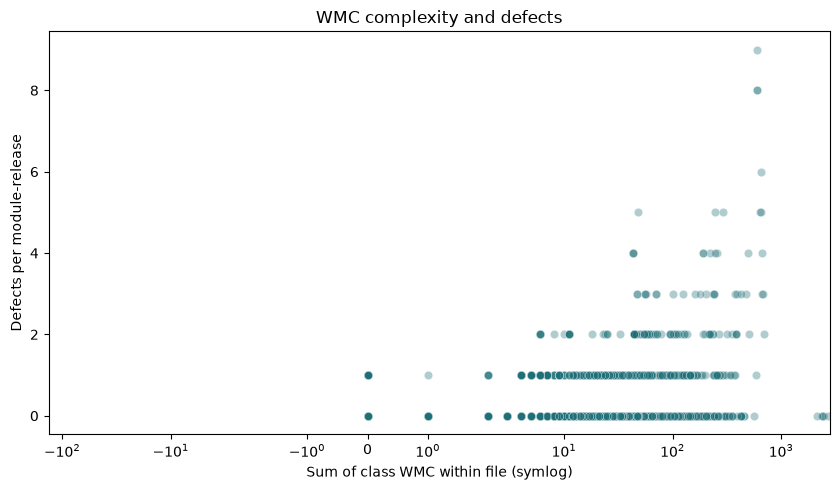

In [4]:
metrics = ["complexity_wmc_sum", "complexity_wmc_avg", "coupling_cbo_sum", "coupling_cbo_avg", "size_loc"]
rows = []
for col in metrics:
    rho, p = spearmanr(df[col], df.defect_count, nan_policy="omit")
    rows.append({"metric": col, "spearman_rho": rho, "n": df[[col, "defect_count"]].dropna().shape[0]})
display(pd.DataFrame(rows).sort_values("spearman_rho", ascending=False))
sample = df.sample(min(6000, len(df)), random_state=28)
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=sample, x="complexity_wmc_sum", y="defect_count", alpha=.35, color="#1f6f78", ax=ax)
ax.set_xscale("symlog"); ax.set(title="WMC complexity and defects", xlabel="Sum of class WMC within file (symlog)", ylabel="Defects per module-release")
plt.tight_layout(); plt.show()

## 4. Change activity, revisions, and contributors
Change volume is derived as total lines added plus total lines deleted. MOSER revision count and distinct authors are proxies for activity. Higher activity can reflect size or development intensity, so these associations do not show that activity causes defects.

,metric,spearman_rho
0,change_volume_proxy,0.229197
1,commit_count_proxy,0.234240
2,contributor_count,0.222137


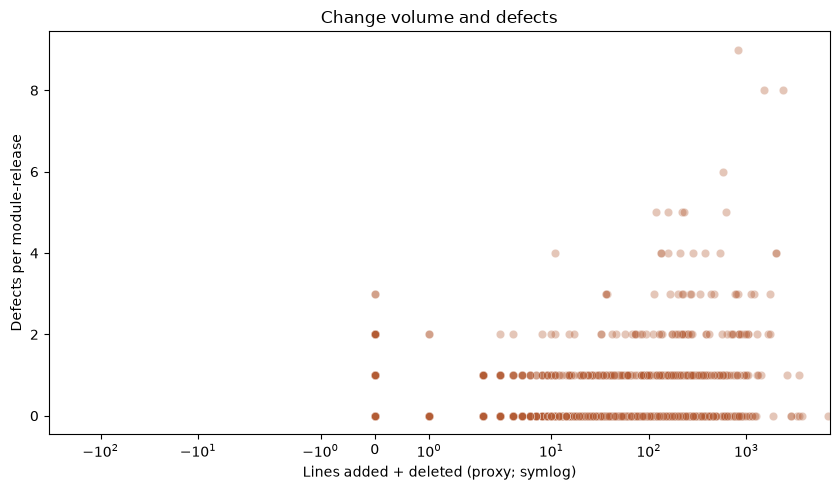

In [5]:
activity = ["change_volume_proxy", "commit_count_proxy", "contributor_count"]
rows = []
for col in activity:
    rho, _ = spearmanr(df[col], df.defect_count, nan_policy="omit")
    rows.append({"metric": col, "spearman_rho": rho})
display(pd.DataFrame(rows))
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.scatterplot(data=sample, x="change_volume_proxy", y="defect_count", alpha=.35, color="#b35c35", ax=ax)
ax.set_xscale("symlog"); ax.set(title="Change volume and defects", xlabel="Lines added + deleted (proxy; symlog)", ylabel="Defects per module-release")
plt.tight_layout(); plt.show()

## 5. Coverage, severity, and release trends
Test coverage is unavailable in this source, so no coverage comparison can be supported. Release dates are also unavailable; charts use version sequence. Severity totals are linked issue-file records after per-file issue deduplication.

,release_version,module_rows,total_defects,modules_with_defects,defects_per_kloc
0,1.0.0,1075,224,178,1.004372
1,1.1.0,1103,145,113,0.636116
2,1.2.0,1108,165,126,0.712229
3,1.3.0,1115,147,112,0.625995
4,1.4.0,1127,155,123,0.645903
5,1.5.0,1176,134,103,0.461730
6,1.6.0,1193,142,107,0.472810
7,1.7.0,1252,179,128,0.578378
8,1.8.0,1301,146,101,0.450819
9,1.9.0,1310,145,90,0.439632


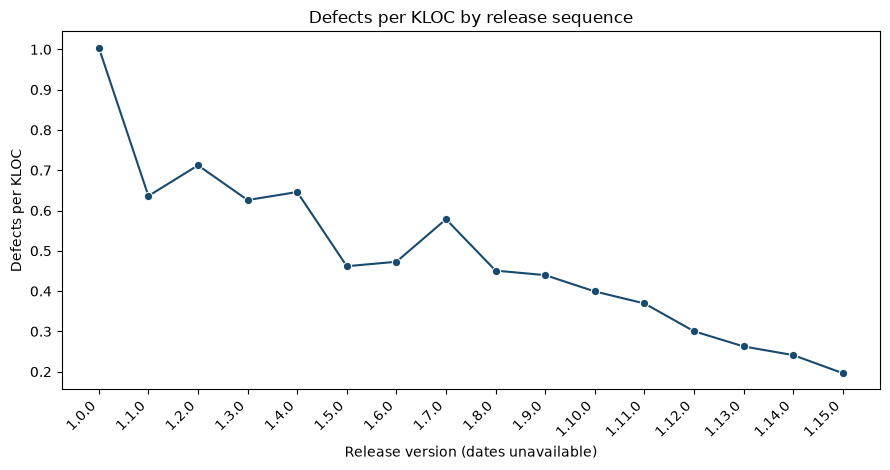

,linked issue-file records
severity,
major,1939
minor,167
critical,21
blocker,11


In [6]:
display(releases[["release_version", "module_rows", "total_defects", "modules_with_defects", "defects_per_kloc"]])
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.lineplot(data=releases, x="release_order", y="defects_per_kloc", marker="o", color="#174a6e", ax=ax)
ax.set_xticks(releases.release_order, releases.release_version, rotation=45, ha="right")
ax.set(title="Defects per KLOC by release sequence", xlabel="Release version (dates unavailable)", ylabel="Defects per KLOC")
plt.tight_layout(); plt.show()
severity_totals = severity.groupby("severity").issue_file_records.sum().sort_values(ascending=False)
display(severity_totals.rename("linked issue-file records").to_frame())

## 6. Findings and interpretation
- 19,751 module-release rows cover 1,644 distinct files across 16 releases.
- The prepared defect labels total 2,138; severity-linked issue counts reconcile to that total after deduplicating issue IDs within file and release.
- WMC complexity, CBO coupling, change volume, revisions, and contributor count show positive descriptive rank associations with defect counts. The correlations are modest and the table is zero-inflated.
- Prioritize recurring files for targeted review and tests, but use recent local evidence and code-owner context before assigning effort.
- Test coverage and calendar dates are absent. Replace this fallback with instructor data if those fields are required for full rubric alignment.

See `data_dictionary.csv`, `cleaning_log.csv`, and `data_quality_report.json` for field definitions and audit results.